# 04 · Rainfall and poverty by district

- **Rainfall:** CHIRPS v2.0 monthly grids (Climate Hazards Center, UC Santa Barbara), about 5 km cells,
  January 1995 to August 2026, clipped to Rwanda (`scripts/fetch_chirps.py`). District means use every cell a
  district touches, so small Kigali districts keep their cells.
- **Poverty:** EICV7 (NISR, 2023/24), Main Indicators Report, Table A9.23.
- **Boundaries:** geoBoundaries RWA ADM2 (CC BY 4.0); district names match the survey's.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from kuhira import style
from kuhira.build import load_poverty
from kuhira.paths import INTERIM
from kuhira.rainfall import dry_season_mm, load_districts, monthly

style.use()
districts = load_districts()
rain = monthly(districts)
rain.to_parquet(INTERIM / "rain_monthly.parquet")
f"{rain.month.size:,} district-months, {rain.mm.isna().sum()} missing"

'11,400 district-months, 0 missing'

## Rwanda's two rainy seasons, and the gap between them
Season A (Sep–Jan) and Season B (Feb–Jun) are rain-fed. June to August is nearly dry; that is where irrigation
turns idle land into a third harvest (Season C).

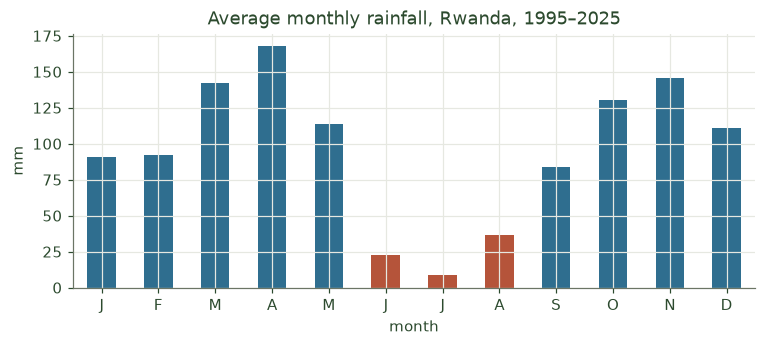

In [2]:
clim = rain[rain.year.between(1995, 2025)].groupby("month").mm.mean()
ax = clim.plot(kind="bar", color=[style.CLAY if m in (6, 7, 8) else style.WATER for m in clim.index], figsize=(8, 3))
ax.set(xlabel="month", ylabel="mm", title="Average monthly rainfall, Rwanda, 1995–2025")
plt.xticks(range(12), list("JFMAMJJASOND"), rotation=0);

## Dry-season rain by district
The east (Kirehe, Bugesera, Ngoma, Kayonza) gets under 40 mm across June–August; the north-west volcano
districts get three times that. Less dry-season rain = more need for water, so it raises a district's score.

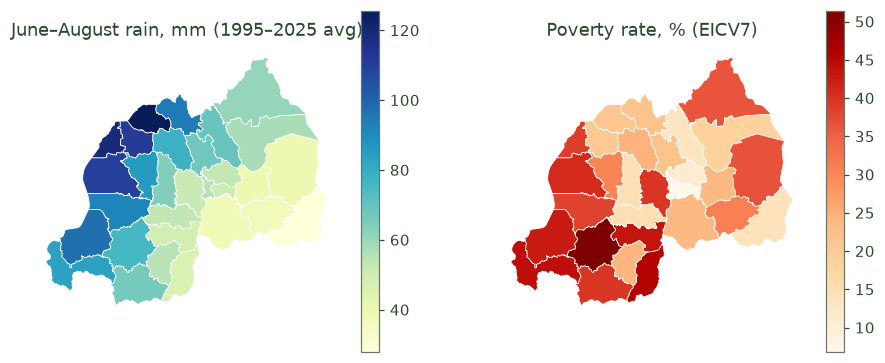

In [3]:
dry = dry_season_mm(rain).rename("dry_season_mm")
geo = districts.merge(dry, on="district").merge(load_poverty().rename("poverty_rate_pct"), on="district")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
geo.plot("dry_season_mm", cmap="YlGnBu", legend=True, ax=axes[0], edgecolor="white", linewidth=0.5)
geo.plot("poverty_rate_pct", cmap="OrRd", legend=True, ax=axes[1], edgecolor="white", linewidth=0.5)
axes[0].set_title("June–August rain, mm (1995–2025 avg)")
axes[1].set_title("Poverty rate, % (EICV7)")
for a in axes:
    a.set_axis_off()

## Are dry places also poor?
Not in a simple way: the dry east is mid-poverty, while the poorest districts (Nyamagabe, Nyaruguru, Karongi)
are wetter highlands. The two factors pull in different directions, which is why the planner lets you weight them.

np.float64(0.22)

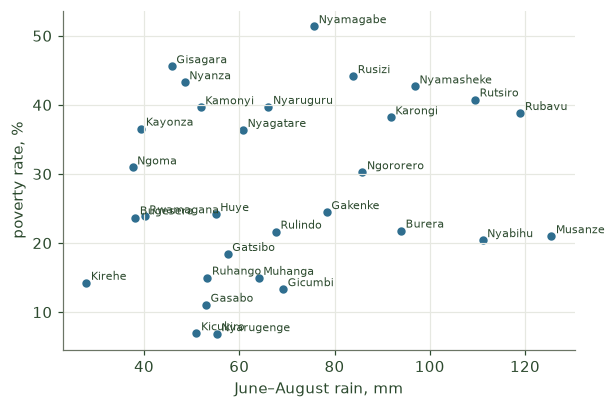

In [4]:
ax = geo.plot.scatter("dry_season_mm", "poverty_rate_pct", color=style.WATER, figsize=(6, 4))
for _, r in geo.iterrows():
    ax.annotate(r.district, (r.dry_season_mm, r.poverty_rate_pct), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set(xlabel="June–August rain, mm", ylabel="poverty rate, %");
geo[["dry_season_mm", "poverty_rate_pct"]].corr().iloc[0, 1].round(2)